# W51 saturated-pixel recovery: questions and answers

2026-10-21

The questions raised while building the gradient-boosting training set, in the order they came up, with the answers we reached and the evidence behind them. Figures are copied from the two report notebooks:

* `report_training_set_audit_20261016.ipynb`: audit of the June run, code fixes, class balance, PSF-fit quality, 4QPM idea
* `report_v2_training_set_20261020.ipynb`: the v2 run and its label check

Terms used throughout:

* **`sat_level`**: the first ramp group (0-4) flagged saturated. It also equals the number of unsaturated groups.
* **label**: the ground-truth flux of a saturated pixel, from the PSF fit.
* **`cal` value**: the pipeline's flux for the same pixel in the `_cal.fits` file.

## 1. Does the PSF fitting of saturated stars work, and are its fluxes fit for training?

**The fit works for isolated stars, but the June training set had two label bugs.** It held 480 tables, 2,048,321 saturated-pixel rows and 25,662 sources, all written on 2026-06-26.

**Bug 1: cross-star contamination.** For each source the code took an 81 px cutout and labelled every pixel flagged `SATURATED` anywhere in that cutout. The selection was `dq & SATURATED` over the whole cutout, not only the fitted source's pixels. In a crowded field the cutout often holds other saturated stars or saturated extended emission, and their pixels received the fitted star's model flux.

| Evidence | June value |
| --- | --- |
| `dist_to_peak` (pixel to fitted center), median / max | 21.7 px / 116 px |
| rows within 5 px of the fitted center | 40% |

**Fix:** `idx_saturated_in_cutout &= (sources[y0:y1, x0:x1] == ii + 1)`, so only the fitted source's connected region is labelled. Each other region gets its own fit in its own loop iteration.

**Bug 2: `fluxerr` on the wrong scale.** The code summed squared terms (`model_err += (psf_eval * flux_err)**2`) and stored that sum, a variance, as `fluxerr`. The median of `flux / fluxerr` was about 2e-5, which no SNR can be. **Fix:** `fluxerr = sqrt(model_err)`. A second error in the same line turned up later (question 12).

**Two more observations, not treated as bugs:**

* 9% of rows have a non-monotonic ramp `DN0`-`DN4`; cosmic rays or RC pixels are plausible causes.
* `nl_strength` is negative for 28% of rows. Its formula, `1 - min(curvatures)`, allows that when the curvature of the early groups is positive or noisy.

The figure shows the contamination tail and a second problem, taken up in question 4: fit confidence falls as the saturated area grows (Spearman rho = -0.46).

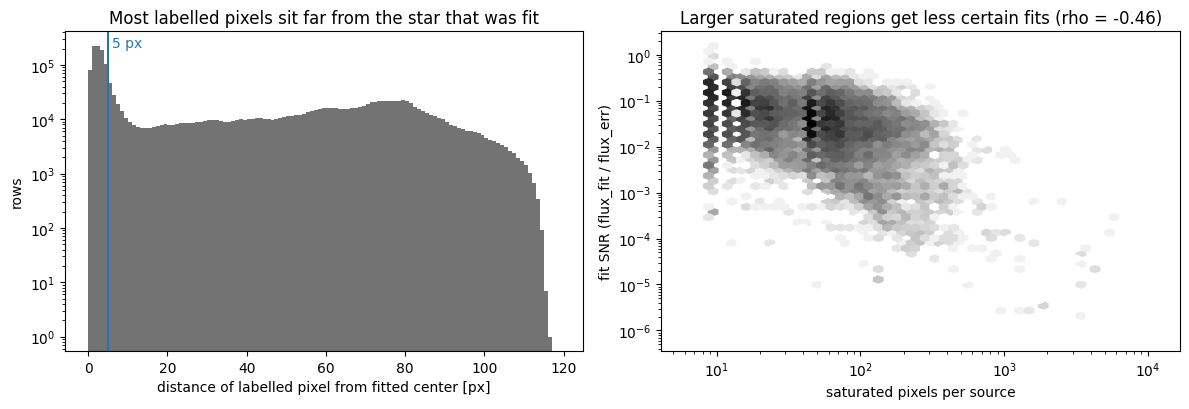

*June run. Left: distance of labelled pixels from the fitted center (5 px marked). Right: saturated pixels per source against fit SNR.*

## 2. Can each `sat_level` have the same number of training rows, so the set is not biased?

**Yes, but the sampling has to be per source, not per pixel.** June counts:

| `sat_level` | NIRCam rows | MIRI rows | sources |
| --- | --- | --- | --- |
| 0 | 66,626 | 70,519 | 3,589 |
| 1 | 628,161 | 31,924 | 11,277 |
| 2 | 390,458 | 46,024 | 13,260 |
| 3 | 368,703 | 73,239 | 16,812 |
| 4 | 372,667 | 0 | 19,402 |

Level 0 is the scarcest, so a uniform set has at most about 137,000 rows per level. Three things make naive downsampling risky:

1. **Pixels of one star are near-copies.** Neighbouring pixels at the same level have nearly the same ramp and label, so 50 pixels from one star are not 50 independent samples.
2. **A few regions dominate.** The top 10 sources supplied 18% of the level-0 rows, almost all from a few heavily saturated MIRI F1000W frames. Random sampling would pull most of the level-0 examples from those regions.
3. **Some cells are empty.** F560W and F1000W were all level 0 in June, and MIRI has no level-4 rows (question 9). Balance within one filter, or within MIRI, is impossible for some levels.

**Recommended sampler:** cap the rows per (source, level) pair, then downsample each level to a common count. A trial with a cap of 30:

| `sat_level` | NIRCam | MIRI | sources |
| --- | --- | --- | --- |
| 0 | 57,321 | 5,297 | 3,589 |
| 1 | 61,834 | 784 | 11,007 |
| 2 | 61,725 | 893 | 12,529 |
| 3 | 61,467 | 1,151 | 15,098 |
| 4 | 62,618 | 0 | 16,667 |

That gives 62,618 rows per level, and the top 10 sources drop to 0.5% of level 0. MIRI shrinks to 1-3% of each level, because a few MIRI sources held most of its rows. **Balance NIRCam and MIRI separately** to keep MIRI data.

Questions 12 and 13 change this: a label-quality cut comes first, and it removes many MIRI rows.

## 3. What other features could the model use?

Suggested, none implemented yet. The current features are `DN0`-`DN4`, slopes, curvatures, `nl_strength`, `max_DN`, `mean_DN`, wavelength, bandwidth, instrument, detector and `dist_to_peak`.

| Feature | Why it helps |
| --- | --- |
| PSF model value at the pixel / star's fitted flux | The fraction of the star's flux the model expects there; already in memory as `model_image`. Likely the strongest single predictor. |
| per-pixel saturation threshold (CRDS `SATURATION`) | Full well varies pixel to pixel; says how deep into saturation a DN reading is. |
| non-linearity coefficients (CRDS `LINEARITY`) | The ramp curvature the model infers is generated by these; separates detector non-linearity from saturation. |
| local background level | Background offsets the ramp and shifts when a pixel saturates. Now stored as `local_bkg` (question 8). |
| read noise and dark current | Sets how reliable the early-group slope is. |
| amplifier ID, column within the amplifier | NIRCam's 4 readout amplifiers differ in bias and 1/f noise. |
| detector row and column | Flat field and intra-pixel effects (brighter-fatter) vary across the array. |
| area and compactness of the parent saturated region | A reliability indicator (questions 4 and 12); can also serve as a QC weight. |

## 4. When the saturated region is very large, for example two stars merged into one region, the PSF fit is uncertain. Can we catch those cases?

**Yes: `area_ratio` catches them on the calibration exposure.** It compares the observed saturated footprint with the footprint the fitted point-source model would produce:

```
area_ratio = area_saturated / (number of model pixels above the cutout's 99th percentile)
```

A clean stellar core has a saturated area close to the model's footprint. A region that merges a star with contiguous extended emission or a second star is much larger than any point source could produce.

Calibration: all 12 saturated sources in `jw06151002001_02105_00004_mirimage` (F1000W). The verdicts come from the cutouts in the figure.

| Source | saturated area (px) | model footprint (px) | `area_ratio` | Appearance | Result |
| --- | --- | --- | --- | --- | --- |
| 5 | 1,777 | 127 | 14.0 | saturated ridge in extended emission | rejected |
| 4 | 808 | 85 | 9.5 | irregular, beside a masked region | rejected |
| 6 | 135 | 20 | 6.8 | elongated streak on a bright ridge edge | kept, borderline |
| 7 | 38 | 21 | 1.8 | compact core | kept |
| 10 | 28 | 149 | 0.2 | compact core, diffraction pattern | kept |

Sources with `area_ratio` > 8.0 are skipped, and the value is stored as a column. In the same exposure, sources 8, 9, 11 and 12 look like compact cores but are dropped by the HOT-pixel check; sources 1 and 2 are dropped by the fit-SNR check; source 3 lies in a fully masked region, so its fit fails.

**Limit:** the 8.0 threshold rests on 12 sources from one exposure, and source 6 at 6.8 sits close to it.

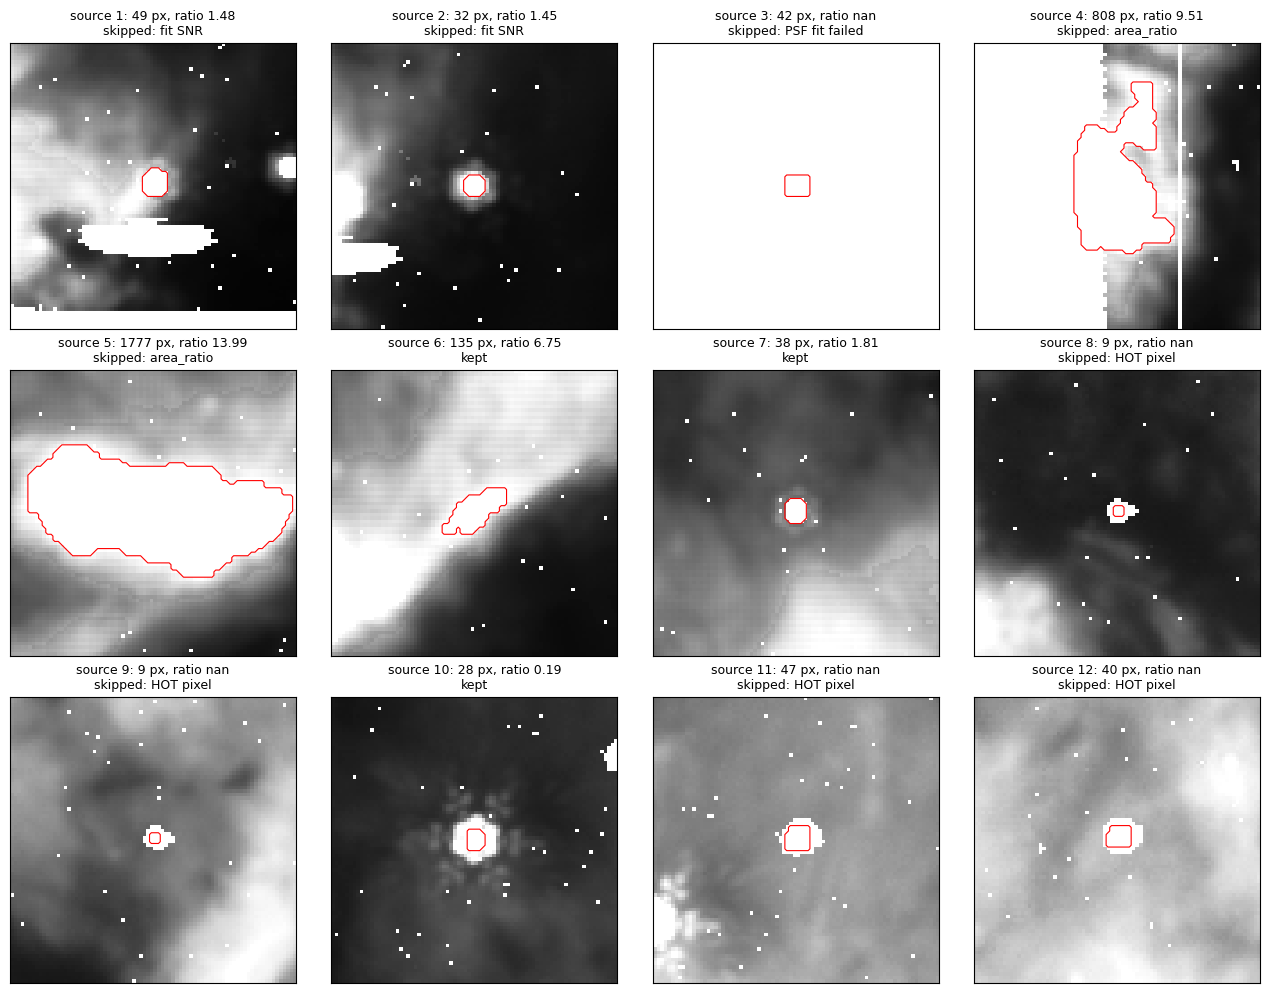

*Saturated region (red contour) of each of the 12 sources on its cal cutout, with area_ratio and the pipeline outcome.*

## 5. If one PSF is fit to two merged stars, the residual sidelobes should show a large flux discrepancy. Can that flag the failures, with the check region scaled to the saturated area?

**We tried two forms of this test, and neither separated good from bad sources in W51.**

**Version 1: azimuthal asymmetry.** The residual (`cutout - model`) in an annulus outside the saturated mask was split into 8 sectors around the fit center, and the spread of the sector means was measured in units of the background noise. The merged source 4 scored 0.62, *below* the clean sources 6 (0.83) and 7 (1.07). The background around source 4 is bright but smooth, so it is roughly symmetric around the source even though it ruins the fit.

**Version 2: total residual flux, as you proposed.** The annulus was sized from `area_saturated` (outer radius from 2 x the effective radius sqrt(area / pi), at least 3 FWHM), and the statistic was the summed residual flux in noise x sqrt(n_pixels) units.

| Normalization | clean sources 6, 7 | merged sources 4, 5 |
| --- | --- | --- |
| noise of the whole cutout | 163, 207 | 150, 218 |
| local median and noise of the annulus itself | 10, 66 | 21, 13 |

The ranges overlap in both cases, and in the second a clean source scores higher than both merged ones. **Why:** dividing by sqrt(n_pixels) assumes independent pixel noise. W51's diffuse emission is spatially correlated over many pixels, so a sum over many correlated pixels looks significant whether or not the fit failed. A usable version needs an effective number of independent pixels, estimated from the background's correlation length.

**Where it stands:** the statistic is kept as the `sidelobe_residual_snr` column, sized adaptively from the saturated area as you suggested, but it does not filter. The geometric `area_ratio` (question 4) is the filter, because it does not depend on a noise model.

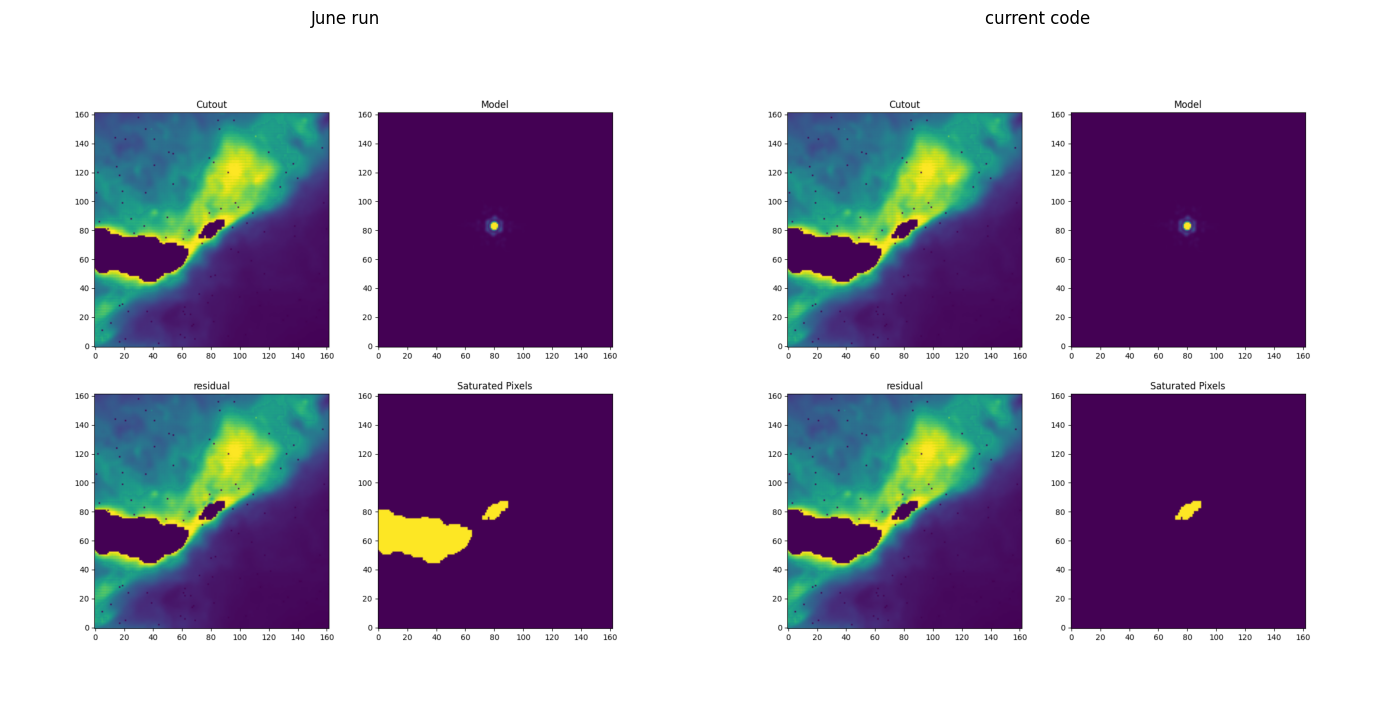

*Source 6 in the June run (left: all saturated pixels in the cutout labelled) and after the cross-star fix (right: only its own region). The extended band in the lower left is source 5.*

## 6. The 4QPM panes have low throughput, so a pixel saturated in the imager may stay unsaturated in a pane. Can the pane's unsaturated ramp be the ground truth?

**For part of the pixels, and mostly not the ones that need it.** In full-frame MIRI imaging the three coronagraph panes record the same filter at 0.2-0.9 of the imager throughput. Your calibration in `w51_miri_cal_claude` (`derive_4qpm_calibration.py`, per-quadrant gains, 5-8% scatter) and `satrec_samples.py` already give a pane "truth" `T` at the same sky for every exposure pixel.

| First saturated group | exposure-pixel rows with pane truth (5 MIRI filters) | Note |
| --- | --- | --- |
| 0 | 0 | the panes saturate there too |
| 1 | 4,463 | 4,432 at F2100W, only for group-0 signal <= 35,000 DN |
| 2 | 62,950 | 60,823 at F2100W |
| 3 | 99,371 | mostly F770W and F2100W |
| 4 | 101,793 | mostly F770W, F1280W, F2100W |

* **Groups 2-4:** the slope of the unsaturated groups already agrees with the panes to 2-8% (`saturation_recovery.ipynb`), so pane labels there mainly *validate*.
* **What panes add:** labels for diffuse emission, where PSF fits fail and `area_ratio` discards the source, and a PSF-free check of PSF labels.
* **Limits:** pane vs imager scatter of +-5-10% (16-84%) on unsaturated pixels; the linear pane calibration runs about 6% low above ~1000 MJy/sr at F2100W; the pane PSF is broader (Lyot stop) and smooths compact cores; MIRI only.
* The pane tables used `jwst_new_cal_claude` ramps; labels and ramp features must come from one Detector1 configuration (question 7).

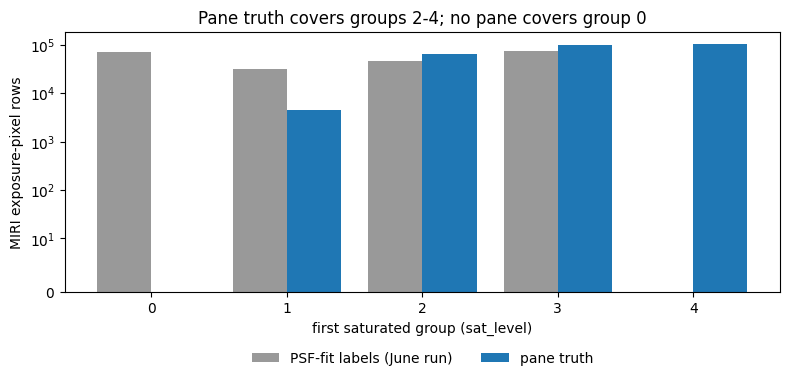

*MIRI rows per first saturated group: PSF-fit labels (June run, grey) and pane truth (blue).*

## 7. Which Detector1 setup should the MIRI ramps use?

**The `jwst_new_cal_claude` settings with the `saturation` step turned on**, so saturated groups are not used in the slope fit. The products are in `/orange/adamginsburg/w51/jwst/jwst_new_cal_claude_satstep/<FILTER>/pipeline_4qpm/` (`run_report_satstep.ipynb`):

* `saturation` on (jwst defaults, including `n_pix_grow_sat=1`), `firstframe` and `rscd` skipped, `lastframe` on, `suppress_one_group=False`
* 16 `cal` and `ramp` files per filter, the same exposures as the original reduction

NIRCam keeps the original pipeline products, which already ran `saturation` with defaults.

**The v2 run** (`making_training_set.py` at `59fd1d9`, `TRAIN_DIR/v2/`): 480 tables, 1,179,223 rows, 31,454 sources.

Two code changes were needed for the new paths:

* exposure IDs are parsed from the file's basename, because the new directory names contain underscores and broke `fn.split("_")`
* the output goes to a separate `v2/` folder, so the June tables stay for comparison

The jobs were moved from the burst QOS to `astronomy-dept` with a 4 h limit, because they sat pending for over an hour; the run script itself still asks for the burst QOS and 96 h.

## 8. Why were the first v2 MIRI labels 2-3.5x below the pipeline values?

**The labels did not include the background.** `PSFPhotometry` is configured with `localbkg_estimator=LocalBackground(15, 30)`. It subtracts the median of a 15-30 px annulus before fitting, so `flux_fit x PSF` describes the star alone. The ramp, and the `cal` value, record star *plus* the bright W51 diffuse emission.

The signature was a trend with `sat_level`. Pixels that saturate late are fainter, so the background is a larger share of their flux and the missing part grows:

| `sat_level` | median label / `cal`, before | background share of `cal` | median label / `cal`, after |
| --- | --- | --- | --- |
| 1 | 0.60 | 0.17 | 0.79 |
| 2 | 0.40 | 0.28 | 0.74 |
| 3 | 0.28 | 0.40 | 0.77 |

**Fix (`59fd1d9`):** `label = model_image + result['local_bkg']`, and `local_bkg` is stored as its own column. The first v2 run was cancelled and all 15 filters were rerun. The remaining MIRI shortfall of about 25% is explained in question 12.

## 9. Why does the training set have no MIRI level-4 rows?

**Candidates come from the `cal` DQ `SATURATED` flag, which is never set when only group 4 saturates.** One satstep exposure (F1000W):

| first saturated group | pixels | `cal` DQ `SATURATED` | `cal` value finite |
| --- | --- | --- | --- |
| 0 | 3,014 | 3,014 | 0 |
| 1 | 12,349 | 12,349 | 11,050 |
| 2 | 12,468 | 12,468 | 9,877 |
| 3 | 12,370 | 12,370 | 8,345 |
| 4 | 11,552 | 0 | 6,043 |

For MIRI, `lastframe` drops group 4 from the fit anyway, so a pixel that saturates only there keeps 4 good groups and gets an ordinary slope. Ramp fitting therefore does not flag it in the pixel DQ. These pixels need no recovery, so the selection stays as it is. The pane tables (question 6), which take their first saturated group from the ramp directly, do contain MIRI group-4 rows.

## 10. Why did the distance of labelled pixels from the fitted center change between the two runs?

**Because of the cross-star fix in question 1.** `dist_to_peak` is the distance from a labelled pixel to the center of the PSF fit that produced its label.

* **June:** each fit labelled every saturated pixel in its 81 px cutout. Pixels of neighbouring stars and of saturated extended emission got the fitted star's model flux, evaluated 10-116 px from its center.
* **v2:** each fit labels only its own connected saturated region.

| | June | v2 |
| --- | --- | --- |
| rows | 2,048,321 | 1,179,223 |
| sources | 25,662 | 31,454 |
| `dist_to_peak` median / max | 21.7 / 116 px | 2.8 / 65 px |
| rows within 5 px of the fitted center | 40% | 87% |
| saturated px per source, median / max | 45 / 11,452 | 23 / 3,176 |

v2 has fewer rows (the contaminating labels are gone) but more sources. The MIRI satstep files flag more pixels, partly through `n_pix_grow_sat`, so more regions become candidates.

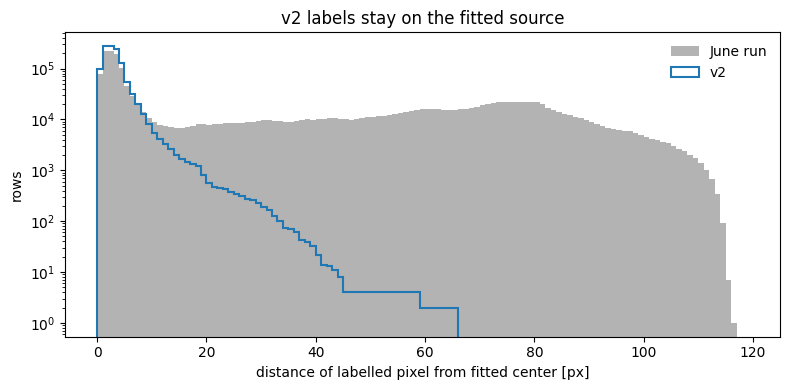

*Distance of labelled pixels from the fitted center, June run (grey) and v2 (blue).*

## 11. The `saturation` step is on, so how can a saturated pixel have a valid `cal` value? Are pixels with 2 unsaturated groups not flagged?

**They are flagged. The `saturation` step works per group, not per pixel.**

1. A ramp has 5 groups (reads). The step compares each group with the pixel's saturation threshold.
2. If the pixel crosses the threshold in group k, groups k, k+1, ... are flagged `SATURATED` in `GROUPDQ`, and the pixel's DQ in the `cal` file also gets `SATURATED`. That flag is how `making_training_set.py` selects candidates.
3. Ramp fitting drops the flagged groups and fits the slope to groups 0 ... k-1, which were read *before* the pixel saturated.

So `sat_level` = k is also the number of unsaturated groups:

| `sat_level` | groups in the fit | `cal` value |
| --- | --- | --- |
| 0 | none | NaN: nothing to fit (NIRCam keeps a value in 15% of these, not investigated) |
| 1 | group 0 only | one-group estimate (`suppress_one_group=False`), less reliable |
| 2 | groups 0-1 | slope from 2 groups: an ordinary measurement |
| 3 | groups 0-2 | slope from 3 groups |
| 4 | groups 0-3 | slope from 4 groups (MIRI: never a candidate, question 9) |

**Consequences:**

* At `sat_level` 2-4 the pipeline already measures the pixel's flux from its own ramp, independent of the PSF fit. That makes those pixels a test of the labels (question 12). Recovery is needed most at levels 0-1.
* The step also flags the **neighbours** of a saturating pixel (`n_pix_grow_sat=1` by default), whether or not they saturate. Some candidates are therefore not saturated at all; their slope is unbiased but uses fewer groups.
* In the table of question 9, 11-48% of pixels with unsaturated groups still have a NaN `cal` value. They carry `NO_FLAT_FIELD` and `DO_NOT_USE`, and 67-97% of them lie at x < 360, the coronagraph side of the detector, where Image2 has no imager flat field.

## 12. Some pixels have a large difference between the PSF-fit label and the `cal` value. What causes it, and does it matter?

**The labels are right near the star's peak. The disagreement sits in pixels far from the peak, where the label is mostly the background value.** Rows with `sat_level` 2-4 and a finite `cal` value (668,903 NIRCam, 16,131 MIRI):

| | NIRCam | MIRI |
| --- | --- | --- |
| median label / `cal` | 0.98-1.01 | 0.74-0.79 |
| rows outside a factor 1.5 | 8.4% | 39.4% |
| rows outside a factor 2 | 3.1% | 19.0% |
| share of the variance between sources (rest: within a source) | 0.29 | 0.61 |

**By distance from the fitted center** (median ratio; fraction outside 0.67-1.5):

| distance | NIRCam | MIRI |
| --- | --- | --- |
| 0-1 px | 1.000; 0.5% | 1.054; 1.4% |
| 1-2 px | 0.986; 1.5% | 0.936; 7.9% |
| 2-3 px | 0.995; 8.8% | 0.818; 24% |
| 3-5 px | 0.959; 13.5% | 0.824; 34% |
| 5-10 px | 0.895; 22% | 0.738; 45% |
| 10-70 px | 1.115; 35% | 0.679; 50% |

**By `psf_share`**, the fraction of the label carried by the PSF model (question 14):

| `psf_share` | NIRCam | MIRI |
| --- | --- | --- |
| < 0.25 | 0.940; 14.5% | 0.610; 64% |
| 0.25-0.5 | 0.965; 8.3% | 0.691; 47% |
| 0.5-0.75 | 0.977; 6.3% | 0.838; 31% |
| 0.75-0.9 | 0.977; 8.5% | 0.935; 23% |
| > 0.9 | 0.993; 8.2% | 0.998; 12.5% |

**Why.** A label is `flux_fit x PSF + local_bkg`. Far from the peak the PSF term is small, so the label is close to a single background number from a 15-30 px annulus. The real pixel also holds whatever else is inside the saturated region:

* extended emission brighter than the annulus median
* a neighbouring star merged into the same region
* a diffraction spike

One PSF plus a flat background cannot model those. MIRI runs low there. NIRCam runs *high* beyond 10 px (median 1.1, about 2 beyond 25 px), probably where the annulus background exceeds the local level (not checked).

**Why MIRI is hit harder.** Its saturated regions are larger and sit in bright extended emission. Even at `sat_level` 0 only 39% of MIRI rows lie within 3 px of the peak (88% for NIRCam), and 73% of the testable MIRI rows lie beyond 3 px. Per MIRI filter the median ratio is 0.86 (F560W), 0.88 (F770W), 0.46 (F1000W), 0.62 (F1280W) and 0.72 (F2100W). The worst sources are the same F1000W regions in each dither, at `area_ratio` 2-4 with ratios near 0.2.

**A second `fluxerr` bug.** `psf_eval` already includes the star flux, so `model_err += (psf_eval * flux_err)**2` multiplied by the flux twice; the stored `fluxerr` was the true error x `psf_star_flux`. Fixed in `a7cab72`; the v2 tables were not regenerated, so divide their `fluxerr` by `psf_star_flux`. Corrected, the star-level SNR runs 22-2,300 (5-95%, minimum 1.03, matching the SNR > 1 cut). The per-pixel error is 0.2% (NIRCam) and 0.8% (MIRI) of the label. The 10-15% NIRCam scatter against `cal` is therefore **systematic** (PSF model, centroid, background), and `fluxerr` does not describe it.

**Does it matter?** For NIRCam, little: medians stay within 1-2% out to 3 px, and the outliers are mostly outer pixels of large regions. For MIRI, yes: about 40% of the testable rows are off by more than a factor 1.5, and a model trained on them would learn to underpredict. The fix is a *selection* of reliable rows (question 13); the fitting method itself holds up near the peak.

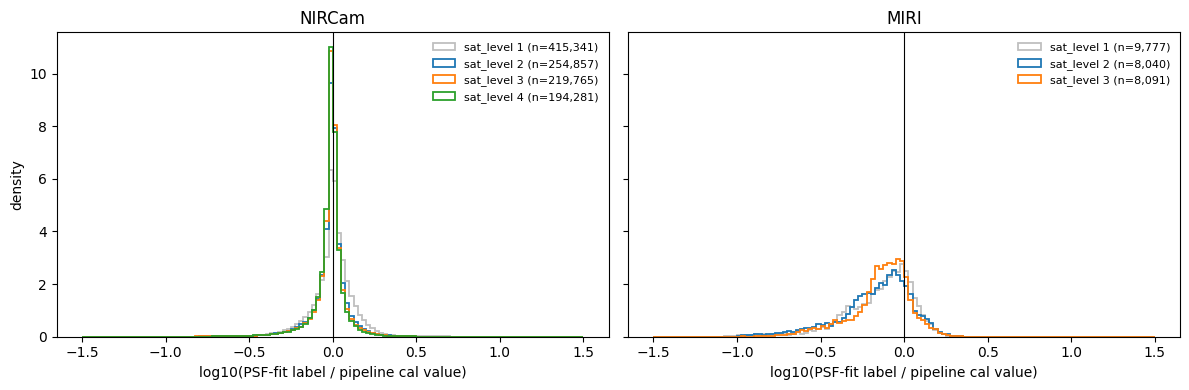

*PSF-fit label / pipeline cal value for rows with a finite cal value, by sat_level.*

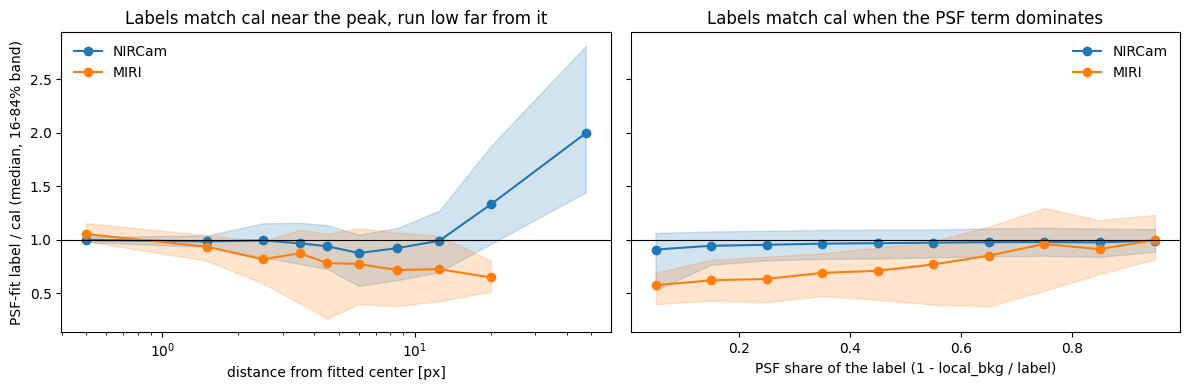

*Median and 16-84% band of label / cal against distance from the fitted center (left) and psf_share (right).*

## 13. What are the next steps, in more detail?

The open items fall into four groups: **A**, label quality, to decide before any training; **B**, cheap code fixes; **C**, an extra label source; **D**, assembling the gradient-boosting input.

| # | Item | Group | Effort | Needs your decision | Depends on |
| --- | --- | --- | --- | --- | --- |
| 4 | `fluxerr` correction | B | free (divide on load) or ~2 h rerun | rerun or not | - |
| 1 | label selection (`psf_share` cut) | A | a few lines at assembly | threshold | - |
| 3 | treatment of level 0 | A | a few lines at assembly | keep / cut / drop, per instrument | - |
| 2 | target at `sat_level` 2-4 | A | a column choice | PSF label or `cal` value | 1 |
| 9 | per-source cap, balancing, split | D | a short function | cap size | 1, 2, 3 |
| 5 | "flux change > 20%" check | B | delete, or rewrite | delete or rewrite | - |
| 6 | HOT-pixel check | B | one line + rerun | yes / no | rerun |
| 7 | `area_ratio` threshold | B | plot review | threshold | 1 |
| 8 | 4QPM pane truth | C | matching by sky position | whether to include | 2 |

**Suggested order:** 4 -> 1 and 3 -> 2 -> 9, then train a first model. Items 5-8 can wait; 6 and 7 only matter if the tables are regenerated.

### A. Label quality (decide before any training)

**1. Choose which labels to keep (`psf_share` and/or `dist_to_peak` cut).**

* *Why:* a label is reliable when the PSF model carries it. Where the PSF part is above 90% of the label, label / `cal` medians are 0.99 (NIRCam) and 1.00 (MIRI). Where `local_bkg` dominates, MIRI labels run about 40% low (question 12).
* *How:* filter rows when the ML input is assembled. `making_training_set.py` and its tables need no change, because `flux`, `local_bkg` and `dist_to_peak` are already columns.
* *Cost:* fraction of rows each cut keeps.

| cut | NIRCam, level 0 / 1 / 2 / 3 / 4 | MIRI, level 0 / 1 / 2 / 3 |
| --- | --- | --- |
| `psf_share` > 0.75 | 0.97 / 0.83 / 0.72 / 0.65 / 0.63 | 0.84 / 0.55 / 0.32 / 0.18 |
| `dist_to_peak` < 3 px | 0.88 / 0.40 / 0.62 / 0.64 / 0.66 | 0.39 / 0.28 / 0.19 / 0.17 |
| both | 0.86 / 0.38 / 0.51 / 0.52 / 0.52 | 0.39 / 0.24 / 0.13 / 0.09 |

* *Suggestion:* use `psf_share`. It measures the actual problem (how much of the label is model rather than background) and keeps more rows. A pixel-distance cut treats NIRCam and MIRI PSFs as the same size, although the MIRI PSF is several times wider.
* *Your decision:* the threshold. 0.75 is a starting point; a stricter cut costs MIRI levels 2-3 most.

**2. Use the `cal` value as the label at `sat_level` 2-4?**

* *Why:* those pixels keep 2-4 unsaturated groups, so the pipeline slope is a direct measurement of their flux (question 11). Far from the peak it is more trustworthy than a PSF prediction.
* *Trade-off:* the model then learns the pipeline's slope at those levels, which is the behaviour wanted there. The cost is losing the only place where PSF-fit labels can be checked against an independent value.
* *Option:* keep both columns, train on the `cal` value at levels 2-4, and keep the PSF label for validation.
* *Your decision:* which label is the training target at levels 2-4.

**3. Decide how to treat level-0 pixels.** This corrects an earlier statement, taken from the MIRI-only `saturation_recovery.ipynb`, that level-0 ramps carry no flux information.

* *NIRCam:* level-0 `DN0` spans 3,800-52,800 (5-95%) and has Spearman 0.78 with the label. A NIRCam group averages several frames, so a group flagged saturated can still hold signal from frames read before saturation.
* *MIRI:* the median level-0 `DN0` is 58,900, on the hard plateau, so most rows carry no information. The 5% below 21,000 are probably grown neighbours (`n_pix_grow_sat`) that never saturated, and they likely produce the Spearman 0.63.
* *Suggestion:* keep NIRCam level 0. For MIRI level 0, keep only pixels below the plateau (a `DN0` cut) or drop it.
* *Caveat:* a correlation is not proof of predictive power, since part of it may come from position in the source (brighter stars saturate more pixels). The trained model's level-0 validation error is the real test.
* *Your decision:* keep, cut or drop, per instrument.

### B. Code fixes (cheap)

**4. `fluxerr`.** The code is fixed (`a7cab72`), but the v2 tables hold `fluxerr` x `psf_star_flux`. Either divide by `psf_star_flux` when loading (free) or regenerate (about 2 h of cluster time). Dividing is enough unless clean files are wanted. A regeneration is worth combining with item 6.

**5. "Flux change > 20%" check.** It never fires: it compares sums over the unsaturated pixels, and the replacement only changes the saturated ones. Either delete it, or rewrite it as a residual test over the unsaturated pixels around the source. Given how the residual tests went in this field (question 5), the suggestion is to delete it and rely on the `psf_share` cut.

**6. HOT-pixel check.** It drops the whole source when any of its saturated pixels is flagged HOT, which removes 11,052 of 62,714 candidates (18%). In the F1000W calibration exposure it dropped 4 of 12 sources that look like compact cores. A gentler version excludes only the HOT pixels from the labels and keeps the rest of the source: a one-line change, but it needs a regeneration run.

**7. `area_ratio` threshold (8.0).** Look through the diagnostic plots of sources with a ratio of 5-10. With the v2 labels, label / `cal` can now also be checked in that range (MIRI medians 0.67-0.78 at ratios 2-8). If the `psf_share` cut already removes the bad pixels, the threshold matters less.

### C. Extra label source

**8. 4QPM pane truth for MIRI.**

* *What it adds:* PSF-free labels at levels 2-4, including diffuse emission where PSF fits fail, and a cross-check of PSF labels.
* *What it does not add:* labels at levels 0-1, where the panes saturate too.
* *How:* the pane truth `T` lives on the sky grid, so it can be matched to the satstep exposures by position. Mark those rows with a `label_source` column.
* *Value:* mainly a cross-check; it adds the most if the model should also learn extended emission.

### D. Assembling the gradient-boosting input

**9. Per-source cap, per-level balancing and the train/test split.** This comes after items 1-3, because the label cut changes the counts per level.

* Cap rows per (source, level), for example 20-30. The trial with 30 in question 2 gave about 62,600 rows per level.
* Downsample each level to a common count, separately for NIRCam and MIRI; otherwise MIRI shrinks to 1-3% of each level.
* Split train and test **by source**, not by pixel, because pixels of one star are near-copies and a pixel split would overstate the accuracy.

## 14. What is `psf_share`?

**The fraction of a label that comes from the PSF model rather than the background:**

```
label     = flux_fit x PSF(pixel) + local_bkg        (the `flux` column)
psf_share = (label - local_bkg) / label = flux_fit x PSF(pixel) / label
```

* `flux_fit`: the star's fitted total flux
* `PSF(pixel)`: the normalized stpsf model evaluated at that pixel
* `local_bkg`: the background photutils measured in a 15-30 px annulus around the star

**How to read it:**

* Near 1, the label is almost all fitted star light. These labels match the pipeline `cal` value (median 0.99 NIRCam, 1.00 MIRI where `psf_share` > 0.9).
* Near 0, the label is mostly the single background number, and any unmodelled structure in the pixel (extended emission, a neighbour) goes into the error.
* It exceeds 1 when `local_bkg` is negative.

It is not stored in the tables; compute it from the `flux` and `local_bkg` columns:

```python
psf_share = (t['flux'] - t['local_bkg']) / t['flux']
```

## 15. Can pixels saturated already in group 0 still be restored from their ramp, for example from its curvature?

This question was put to three independent subagents: a **data analyst** (tests on the v2 tables and raw `uncal` ramps), a **detector physicist** (readout, pipeline logic, literature) and a **skeptic** (how a level-0 model could look good without real information). Their findings agree. Numbers below are theirs; "measured" means checked on our data, "inference" means reasoning not yet tested.

### 15.1 "Level 0" is a mixture of very different pixels

The pipeline flags group 0 as saturated in three ways (stcal): (a) the raw group-0 value R0 is at or above the pixel's saturation threshold; (b) NIRCam only, R0 is above 0.75 x threshold and group 1 is saturated (the frame-averaging "dilution" rule); (c) a 3x3 neighbour of an (a) or (b) pixel (`n_pix_grow_sat=1`). Measured split of level-0 rows with `psf_share` > 0.75 (data analyst, raw R0 against the CRDS threshold):

| class | NIRCam | MIRI | what the ramp holds |
| --- | --- | --- | --- |
| A-hard: R0 >= threshold, ZEROFRAME also saturated | 19% | (all of A: 60%) | NIRCam: nothing, flat at the ADC limit; MIRI: slow rise to a ceiling |
| A-soft: R0 >= threshold, ZEROFRAME unsaturated | 11% | - | the ZEROFRAME, a single unsaturated read |
| B: 0.75-1 x threshold (dilution flag) | 23% | n/a | an ordinary group-0 read |
| C: below threshold, flagged only as a neighbour | 46% | 40% | an ordinary read; not saturated at all |

So for NIRCam about 70% of "level 0" pixels are not saturated in group 0, and for MIRI 40%. This explains most of the Spearman 0.78 between `DN0` and the label found earlier.

The physicist also found **bad pixels** among NIRCam level 0: on one detector (nrca1), 99% of its 1,984 group-0-saturated pixels carry HOT, DEAD or NO_LIN_CORR flags, with flat raw values of 6-20k DN (0-75% across detectors, one exposure each, measured). The HOT exclusion added in `f49be8a` removes part of them; DEAD sources are skipped; NO_LIN_CORR pixels are still included.

### 15.2 What the ramp physically records

**NIRCam** (SHALLOW2: 2 frames averaged per group, 3 skipped, TFRAME = 10.7 s, TGROUP = 53.7 s; measured from headers). Every `uncal` file has a **ZEROFRAME** extension: the first frame, read after one TFRAME. With a usable well of about 48k DN (inference), three regimes follow:

| count rate | group 0 | recoverable from |
| --- | --- | --- |
| < ~2,200 DN/s | unsaturated | the ramp (not really level 0) |
| ~2,200-4,500 DN/s | frame 2 saturated, frame 1 not | the ZEROFRAME: rate = (ZEROFRAME - bias) / TFRAME |
| > ~4,500 DN/s | every read saturated | nothing in the ramp; only spatial information |

The pipeline sets the ZEROFRAME to 0 for flagged pixels, so the processed products discard it; the **raw** ZEROFRAME still has it (it needs superbias, reference-pixel and linearity correction). For truly hard-saturated NIRCam pixels the post-saturation increments are 0 +- 25 DN, i.e. read noise, with no correlation to the label (measured).

**MIRI** (FASTR1, 1 frame per group, TGROUP = 2.775 s, one threshold of 56,660 DN for every pixel). A saturated Si:As pixel loses bias as charge collects ("debiasing"), so its response falls and the ramp approaches a common ceiling of about 62k DN instead of stopping. The ramp is **not flat**: median increments after saturation are about 950 / 230 / 100 / 40 DN (data analyst) or 2,145 / 370 / 124 / 35 DN (physicist, another exposure), far above the ~10 DN increment noise. Brighter pixels sit closer to the ceiling: within one filter the first increment has Spearman -0.52 with the label and the curvature +0.49 (measured). The ceiling value itself is the same for every pixel and carries no flux information. Inference: the signal compresses roughly exponentially, so it ranks pixels near the threshold well and carries little information a few times above it. Confounders: the first-frame and reset anomalies shift group 0, the last-frame effect shifts group 4, and the brighter-fatter effect moves charge from debiased pixels into neighbours.

### 15.3 Predictive test

XGBoost, ramp features only (no `dist_to_peak`, `psf_star_flux` or other fit-derived columns), 5-fold cross-validation grouped by source, `psf_share` > 0.75, target log10(label). Scatter = 16-84% half-width of log10(prediction / label), in dex (0.1 dex = 26%, 0.3 dex = a factor 2):

| subset | filter median only | DN0 + filter | post-saturation increments | all ramp features | raw ZEROFRAME |
| --- | --- | --- | --- | --- | --- |
| NIRCam, all level 0 | 0.537 | 0.177 | 0.379 | 0.162 | - |
| NIRCam A-hard | 0.323 | 0.354 | 0.326 | 0.303 | - |
| NIRCam A-soft | 0.137 | 0.130 | 0.150 | 0.129 | - |
| NIRCam B | 0.183 | 0.146 | 0.191 | 0.145 | 0.136 |
| NIRCam C | 0.300 | 0.138 | 0.180 | 0.127 | 0.113 |
| MIRI, all level 0 | 0.467 | 0.280 | 0.275 | 0.248 | - |
| MIRI A (truly saturated) | 0.463 | 0.341 | 0.333 | 0.292 | - |
| MIRI C (neighbours) | 0.278 | 0.180 | 0.188 | 0.179 | - |
| reference: level 1, all ramp | NIRCam 0.103, MIRI 0.120 | | | | |

* **NIRCam A-hard**: the ramp gains 0.02 dex over the filter median. No usable information, as the physics predicts.
* **NIRCam B, C, A-soft**: 0.11-0.15 dex, close to level 1, because these pixels have a valid read. The raw ZEROFRAME is the best single feature and is not yet in the tables.
* **MIRI A**: the post-saturation increments alone cut the scatter from 0.46 to 0.33 dex, which supports the hypothesis. Most of the gain is ranking pixels *within* a source (within-source Spearman 0.70-0.77); the error on a star's mean level does not improve (0.17 dex vs 0.13 for the filter median). Given the position in the source (`dist_to_peak`, diagnostic only), the ramp reaches 0.13 dex, so it does carry amplitude information.

### 15.4 The skeptic's warnings

1. **Extrapolation** (measured): level-0 labels are much brighter than the rest. For NIRCam the 99.9th-percentile level-0 label is 1.4e6 MJy/sr against 4.8e4 at level 1; per filter 45-57% of level-0 rows lie above the 99th percentile of the level 1-4 labels, and 10-42% above their maximum. A tree model predicts a constant beyond its training range, so the brightest stars cannot be predicted from fainter levels.
2. **Leakage**: `dist_to_peak`, `is_near_peak`, `psf_star_flux`, `local_bkg`, `area_ratio`, `sidelobe_residual_snr`, `x`, `y` all come from the fit or the label and must not be features. Filter or detector identity sets much of the label scale (the "filter median" column above). On the plateau, `DN0` mostly encodes the pixel's threshold, not its flux.
3. **Near-copies across exposures**: the same star appears in 4 dithers and in other filters, so the train/test split should group by **sky position**, not by exposure.
4. **Unverified labels**: the 1% label agreement was measured at levels 2-4. Level-0 pixels are the cores of the brightest stars, where centroid error, the PSF core shape and the brighter-fatter effect matter most, and nothing independent checks them.

### 15.5 Verdict and what it means for the plan

* **The hypothesis holds for MIRI**: debiasing leaves a real, flux-dependent curvature after saturation. Expect about 0.3 dex (a factor 2) per pixel from the ramp alone, better with position information, worse for the very brightest cores.
* **It does not hold for truly hard-saturated NIRCam pixels** (19% of NIRCam level 0): their reads sit at the ADC limit. For those, only the PSF wings (spatial information) constrain the flux.
* **Most NIRCam "level 0" pixels are recoverable anyway**, because they are not saturated in group 0 or have an unsaturated ZEROFRAME.

Proposed next actions (not yet done):

1. Tag each level-0 row by class (A-hard / A-soft / B / C) from raw R0 against the CRDS threshold, and report results per class.
2. Add the raw, bias-subtracted ZEROFRAME as a NIRCam feature; add MIRI increment ratios (they cancel the common ceiling).
3. Exclude pixels with bad-pixel DQ flags (NO_LIN_CORR in addition to HOT).
4. Validate the level-0 labels before trusting any score: inject scaled copies of fainter stars into the saturated regime and refit with the core masked, test centroid shifts of +-0.05-0.1 px, and compare the same star across its 4 dithers.
5. Evaluate with a split by sky position, plus a held-out set of the brightest 20% of stars per filter; report the slope of log(prediction) against log(label) (1 means no ceiling) and the baselines above.

## 16. Decisions on the next steps (2026-10-21) and their status

| # | item | decision | status |
| --- | --- | --- | --- |
| 1 | label selection | keep rows with `psf_share` > 0.75 | applied when the training input is assembled |
| 2 | target at `sat_level` 2-4 | keep both the PSF label (`flux`) and the pipeline value | `cal_value` column added (`f49be8a`), in the v3 run |
| 3 | level 0 | restore level-0 pixels in any case; test whether the ramp trend carries flux | discussed in question 15 |
| 4 | `fluxerr` | explained | fixed in the code (`a7cab72`), correct in the v3 run |
| 5 | "flux change > 20%" check | explained; it never fires | open |
| 6 | HOT pixels | exclude only the HOT pixels from the labels, keep the rest of the source | done (`f49be8a`), in the v3 run |
| 7 | `area_ratio` threshold | explained | to recheck on v3 within `psf_share` > 0.75 |
| 8 | 4QPM panes | label pane pixels like the imager field; mark them | done (`f49be8a`): `in_4qpm`, `fqpm_quadrant` (0 = imager, 1-12 = pane quadrant); pane data from `_bkgm` minus its background offset |
| 9 | assembling the input | explained | split by sky position (question 15) |

v3 run: all 15 filters, `TRAIN_DIR/v3/`, jobs 47065690-47065704.